# Compare product categories

**Purpose:** Select two categories for predicting recorded helpful-vote counts.

Here we use review text, ratings, duplicates, time coverage, matching `parent_asin` metadata, price, product descriptions, and image availability to compare the categories.

**Before running:**
Make sure datasets have been uploaded and verify that their file paths are correctly specified in this notebook( because of large size of datasets, online downloading is not supported. ) 


In [28]:
import gzip
import json
import math
import random
import shutil
import statistics
from collections import Counter
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown, Image, FileLink

SEED = 42
CATEGORIES = [
    "All_Beauty",
    "Appliances",
    "Video_Games",
    "Musical_Instruments"
]
SAMPLE_SIZE = 12_000           # Reviews held in memory per category
MAX_REVIEW_ROWS = None        # Reservoir over entire file

SCORE_WEIGHTS = {
    # Original dataset-quality indicators: 50% total
    "text_coverage": 0.10,
    "long_text_rate_20_words": 0.10,
    "metadata_join_rate": 0.12,
    "price_coverage": 0.03,
    "image_coverage": 0.01,
    "description_coverage": 0.03,
    "rating_entropy": 0.04,
    "product_diversity": 0.02,
    "temporal_coverage": 0.05,

    # Helpful-vote prediction indicators: 50% total
    "helpful_label_coverage": 0.08,
    "nonzero_vote_share": 0.12,
    "votes_5plus_share": 0.06,
    "positive_review_count": 0.04,
    "products_with_10plus_reviews_and_3plus_positive_votes": 0.08,
    "review_share_in_products_with_10plus_reviews": 0.12,
}
assert abs(sum(SCORE_WEIGHTS.values()) - 1.0) < 1e-9

OUTPUT_DIR = Path('/kaggle/working/category_selection')
DOWNLOAD_DIR = Path('/kaggle/working/amazon_raw')

CATALOG = {
    # Published *rounded* review, product, review-token counts
    "All_Beauty": (701_500, 112_600, 31_600_000),
    "Appliances": (2_100_000, 94_300, 92_800_000),
    "Musical_Instruments": (3_000_000, 213_600, 182_200_000),
    "Baby_Products": (6_000_000, 217_700, 323_300_000),
    "Video_Games": (4_600_000, 137_200, 347_900_000),
}

assert SAMPLE_SIZE > 0
assert MAX_REVIEW_ROWS is None or MAX_REVIEW_ROWS > 0
assert len(CATEGORIES) >= 2 and len(set(CATEGORIES)) == len(CATEGORIES)
assert all(c in CATALOG for c in CATEGORIES), 'Unknown category: update CATALOG first.'

print('Kaggle input root exists:', Path('/kaggle/input').exists())
print('Working output:', OUTPUT_DIR)
print('Categories:', ', '.join(CATEGORIES))
print('Image-availability weight:', f"{100 * SCORE_WEIGHTS['image_coverage']:.0f}%")
print('Unified scoring weights:', {name: f'{100*weight:.0f}%' for name, weight in SCORE_WEIGHTS.items()})

Kaggle input root exists: True
Working output: /kaggle/working/category_selection
Categories: All_Beauty, Appliances, Video_Games, Musical_Instruments
Image-availability weight: 1%
Unified scoring weights: {'text_coverage': '10%', 'long_text_rate_20_words': '10%', 'metadata_join_rate': '12%', 'price_coverage': '3%', 'image_coverage': '1%', 'description_coverage': '3%', 'rating_entropy': '4%', 'product_diversity': '2%', 'temporal_coverage': '5%', 'helpful_label_coverage': '8%', 'nonzero_vote_share': '12%', 'votes_5plus_share': '6%', 'positive_review_count': '4%', 'products_with_10plus_reviews_and_3plus_positive_votes': '8%', 'review_share_in_products_with_10plus_reviews': '12%'}


In [29]:
from pathlib import Path

print("Files available in Kaggle:\n")

for path in sorted(Path("/kaggle/input").rglob("*")):
    if path.is_file():
        print(path)

Files available in Kaggle:

/kaggle/input/datasets/sambuddyy/all-beauty-meta/meta_All_Beauty.jsonl
/kaggle/input/datasets/sambuddyy/all-beauty-review/All_Beauty.jsonl
/kaggle/input/datasets/sambuddyy/meta-appliances/meta_Appliances.jsonl
/kaggle/input/datasets/sambuddyy/meta-musical-instruments/meta_Musical_Instruments.jsonl
/kaggle/input/datasets/sambuddyy/meta-video-games/meta_Video_Games.jsonl
/kaggle/input/datasets/sambuddyy/review-appliances/Appliances.jsonl
/kaggle/input/datasets/sambuddyy/review-musical-instruments/Musical_Instruments.jsonl
/kaggle/input/datasets/sambuddyy/review-video-games/Video_Games.jsonl


In [30]:
import gzip
from pathlib import Path

def open_jsonl(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    return opener(path, "rt", encoding="utf-8")


def find_file(category, metadata=False):
    """Find files recursively in Kaggle input directories."""
    root = Path("/kaggle/input")

    stem = f"meta_{category}" if metadata else category

    for ext in (".jsonl.gz", ".jsonl"):
        target = stem + ext
        matches = sorted(root.rglob(target))

        if matches:
            return matches[0]

    return None


def resolve_category_paths(category):
    review_path = find_file(category, metadata=False)
    meta_path = find_file(category, metadata=True)

    if review_path is None:
        print(f"Review file missing for {category}")

    if meta_path is None:
        print(f"Metadata file missing for {category}")

    return review_path, meta_path


available = {}

for category in CATEGORIES:
    review_path, meta_path = resolve_category_paths(category)

    available[category] = (review_path, meta_path)

    print(f"\n{category}:")
    print("  Reviews:", review_path or "NOT FOUND")
    print("  Metadata:", meta_path or "NOT FOUND")


ready = [
    c for c, (r, m) in available.items()
    if r is not None and m is not None
]

print(f"\nReady: {len(ready)} / {len(CATEGORIES)} categories")

if len(ready) < 2:
    print("\nAdd at least TWO categories (both review and metadata files).")


All_Beauty:
  Reviews: /kaggle/input/datasets/sambuddyy/all-beauty-review/All_Beauty.jsonl
  Metadata: /kaggle/input/datasets/sambuddyy/all-beauty-meta/meta_All_Beauty.jsonl

Appliances:
  Reviews: /kaggle/input/datasets/sambuddyy/review-appliances/Appliances.jsonl
  Metadata: /kaggle/input/datasets/sambuddyy/meta-appliances/meta_Appliances.jsonl

Video_Games:
  Reviews: /kaggle/input/datasets/sambuddyy/review-video-games/Video_Games.jsonl
  Metadata: /kaggle/input/datasets/sambuddyy/meta-video-games/meta_Video_Games.jsonl

Musical_Instruments:
  Reviews: /kaggle/input/datasets/sambuddyy/review-musical-instruments/Musical_Instruments.jsonl
  Metadata: /kaggle/input/datasets/sambuddyy/meta-musical-instruments/meta_Musical_Instruments.jsonl

Ready: 4 / 4 categories


## Category scoring: general quality + helpful-vote suitability

**The final score is computed near the end of this notebook, after the full-file vote audit.** 

| General quality metric | Weight | Helpful-vote task metric | Weight |
|:--|--:|:--|--:|
| Text availability | 10% | Valid helpful-vote label coverage | 8% |
| Reviews containing >=20 words | 10% | Fraction of reviews with at least 1 vote | 12% |
| Successful review-to-metadata join | 12% | Fraction of reviews with at least 5 votes | 6% |
| Price availability | 3% | Positive-vote review count (log-scaled, normalized across categories) | 4% |
| Product image availability | 1% | Products with >=10 reviews and >=3 positive-vote reviews (log-scaled, normalized) | 8% |
| Product descriptions / features | 3% | Fraction of reviews associated with products having >=10 reviews | 12% |
| Rating entropy | 4% | | |
| Sampled product diversity | 2% | | |
| Timestamp availability / time span | 5% | | |
| **General total** | **50%** | **Task-specific total** | **50%** |


The nine original data-quality indicators are computed using a 12,000-review reservoir sample per category, as sampling provides efficient estimates of general dataset characteristics without processing every review. In contrast, the six new helpful-vote indicators are calculated from the entire review dataset to obtain accurate counts and proportions, particularly for rare helpful-vote events and product-level review patterns.
For the count-based metrics, we applied `log1p` and min–max normalization across the four compared categories; other metrics are already ratios in [0,1]. A category-independent feature with no variation gets a neutral 0.5 for relative normalization. Finally, the previous duplicate-fingerprint penalty (up to 10 points) is subtracted.


In [31]:
def stream_reservoir(path, k, seed, max_rows=None):
    rng = random.Random(seed)
    sample = []
    valid = invalid = 0
    with open_jsonl(path) as file:
        for line in file:
            if not line.strip():
                continue
            try:
                obj = json.loads(line)
                if not isinstance(obj, dict):
                    raise ValueError("JSON row is not an object")
            except (ValueError, json.JSONDecodeError):
                invalid += 1
                continue
            valid += 1
            if len(sample) < k:
                sample.append(obj)
            else:
                j = rng.randrange(valid)
                if j < k:
                    sample[j] = obj
            if valid % 500_000 == 0:
                print(f'  streamed {valid:,} valid reviews...', flush=True)
            if max_rows is not None and valid >= max_rows:
                break
    return sample, valid, invalid

def nonempty(value):
    if value is None:
        return False
    if isinstance(value, str):
        return bool(value.strip())
    if isinstance(value, (list, dict, tuple)):
        return bool(value)
    return True

def valid_price(value):
    if isinstance(value, (float, int)) and not isinstance(value, bool):
        return math.isfinite(value) and value > 0
    if isinstance(value, str):
        s = value.strip().replace(",", "").replace("$", "")
        try:
            return math.isfinite(float(s)) and float(s) > 0
        except ValueError:
            pass
    return False

def image_available(images):
    if not isinstance(images, list):
        return False
    return any(
        (isinstance(image, str) and image.strip()) or
        (isinstance(image, dict) and any(
            nonempty(image.get(key))
            for key in ("large", "hi_res", "thumb", "large_image_url", "medium_image_url")
        ))
        for image in images
    )

def relevant_metadata(path, desired_parent_ids):
    """Stream complete metadata; keep ONLY products appearing in sampled reviews."""
    found = {}
    invalid = 0
    with open_jsonl(path) as file:
        for line in file:
            if not line.strip():
                continue
            try:
                item = json.loads(line)
                if not isinstance(item, dict):
                    raise ValueError()
            except (ValueError, json.JSONDecodeError):
                invalid += 1
                continue
            pid = item.get("parent_asin")
            if pid in desired_parent_ids:
                found[pid] = item
    return found, invalid

def normalized_rating_entropy(ratings):  # normalized Shannon entropy of ratings
    counts = Counter(r for r in ratings if r in (1, 2, 3, 4, 5))
    n = sum(counts.values())
    return (-sum((v / n) * math.log(v / n) for v in counts.values()) / math.log(5)
            if n else 0.0)

def evaluate(category, reviews_path, meta_path, sample_size, max_rows):
    reviews, scanned, broken = stream_reservoir(
        reviews_path, sample_size, SEED, max_rows
    )
    if not reviews:
        raise ValueError(f"No valid reviews in {reviews_path}")

    pids = {str(r.get("parent_asin")) for r in reviews if nonempty(r.get("parent_asin"))}
    metadata, broken_meta = relevant_metadata(meta_path, pids)
    text_list = [str(r.get("text") or "") for r in reviews]
    text_lengths = [len(text.split()) for text in text_list]
    matched = [metadata.get(str(r.get("parent_asin"))) for r in reviews]
    stars = []
    for r in reviews:
        try:
            stars.append(float(r.get("rating")))
        except (ValueError, TypeError):
            stars.append(float("nan"))
    fingerprints = [(
        str(r.get("user_id") or ""), str(r.get("parent_asin") or ""),
        str(r.get("rating") or ""),
        (str(r.get("text") or "").strip().casefold())
    ) for r in reviews]
    n = len(reviews)
    is_matched = [m is not None for m in matched]
    timestamps = pd.to_datetime(
        pd.to_numeric(pd.Series([r.get("timestamp") for r in reviews]), errors="coerce"),
        unit="ms", utc=True, errors="coerce"
    )
    valid_timestamps = timestamps.dropna()
    temporal_span_months = (
        (valid_timestamps.max() - valid_timestamps.min()).days / 30.44
        if len(valid_timestamps) > 1 else 0.0
    )

    def fraction(predicate):
        return sum(bool(x) for x in predicate) / n

    result = {
        "category": category,
        "published_reviews": CATALOG[category][0],
        "published_products": CATALOG[category][1],
        "published_reviews_per_product": CATALOG[category][0] / CATALOG[category][1],
        "published_tokens_per_review": CATALOG[category][2] / CATALOG[category][0],
        "sample_reviews": n,
        "scanned_reviews": scanned,
        "bad_review_lines": broken,
        "bad_metadata_lines": broken_meta,
        "unique_sampled_products": len(pids),
        "text_coverage": fraction(nonempty(t) for t in text_list),
        "long_text_rate_20_words": fraction(length >= 20 for length in text_lengths),
        "median_review_words": statistics.median(text_lengths),
        "metadata_join_rate": fraction(is_matched),
        "price_coverage": fraction(m is not None and valid_price(m.get("price")) for m in matched),
        "image_coverage": fraction(m is not None and image_available(m.get("images")) for m in matched),
        "description_coverage": fraction(
            m is not None and (nonempty(m.get("features")) or nonempty(m.get("description")))
            for m in matched
        ),
        "subcategory_coverage": fraction(
            m is not None and nonempty(m.get("categories")) for m in matched
        ),
        "review_image_coverage": fraction(image_available(r.get("images")) for r in reviews),
        "valid_rating_rate": fraction(math.isfinite(s) and 1 <= s <= 5 for s in stars),
        "rating_entropy": normalized_rating_entropy(stars),
        "timestamp_coverage": float(timestamps.notna().mean()),
        "sample_timespan_months": round(temporal_span_months, 1),
        "duplicate_fingerprint_rate": 1 - len(set(fingerprints)) / n,
    }
    for star in range(1, 6):
        result[f"rating_{star}_share"] = fraction(s == star for s in stars)

    score_components = {
        "text_coverage": result["text_coverage"],
        "long_text_rate_20_words": result["long_text_rate_20_words"],
        "metadata_join_rate": result["metadata_join_rate"],
        "price_coverage": result["price_coverage"],
        "image_coverage": result["image_coverage"],
        "description_coverage": result["description_coverage"],
        "rating_entropy": result["rating_entropy"],
        "product_diversity": min(1.0, result["unique_sampled_products"] / 1000),
        "temporal_coverage": result["timestamp_coverage"] * min(1.0, result["sample_timespan_months"] / 24),
    }
    # An initial general-quality score is available before the full-file vote audit.
    # Restrict to known indicators and renormalize their shared 50% weight to 100%.
    result.update(score_components)
    general_weight_sum = sum(SCORE_WEIGHTS[key] for key in score_components)
    result["quality_score"] = 100 * sum(
        SCORE_WEIGHTS[key] * score_components[key]
        for key in score_components
    ) / general_weight_sum
    result["quality_score"] -= 10 * result["duplicate_fingerprint_rate"]
    result["quality_score"] = max(0, round(result["quality_score"], 2))
    return result

## Run category audits and rank them


In [32]:
results = []
for category in CATEGORIES:
    review_path, meta_path = available[category]
    if review_path is None or meta_path is None:
        print(f'SKIPPING {category}: reviews or metadata not attached.')
        continue
    print(f'\nAUDITING {category} ...', flush=True)
    results.append(evaluate(
        category, review_path, meta_path, SAMPLE_SIZE, MAX_REVIEW_ROWS
    ))

if len(results) < 2:
    raise RuntimeError('Need at least two categories with review and metadata archives.')

comparison_df = pd.DataFrame(results).sort_values(
    'quality_score', ascending=False
).reset_index(drop=True)

print('\nGENERAL-QUALITY-ONLY TOP TWO (not final):', ', '.join(comparison_df.head(2)['category']))
show_cols = [
    'category', 'quality_score', 'sample_reviews', 'text_coverage',
    'long_text_rate_20_words', 'metadata_join_rate',
    'price_coverage', 'image_coverage', 'rating_entropy',
    'sample_timespan_months', 'duplicate_fingerprint_rate'
]
display(comparison_df[show_cols].round(3))


AUDITING All_Beauty ...
  streamed 500,000 valid reviews...

AUDITING Appliances ...
  streamed 500,000 valid reviews...
  streamed 1,000,000 valid reviews...
  streamed 1,500,000 valid reviews...
  streamed 2,000,000 valid reviews...

AUDITING Video_Games ...
  streamed 500,000 valid reviews...
  streamed 1,000,000 valid reviews...
  streamed 1,500,000 valid reviews...
  streamed 2,000,000 valid reviews...
  streamed 2,500,000 valid reviews...
  streamed 3,000,000 valid reviews...
  streamed 3,500,000 valid reviews...
  streamed 4,000,000 valid reviews...
  streamed 4,500,000 valid reviews...

AUDITING Musical_Instruments ...
  streamed 500,000 valid reviews...
  streamed 1,000,000 valid reviews...
  streamed 1,500,000 valid reviews...
  streamed 2,000,000 valid reviews...
  streamed 2,500,000 valid reviews...
  streamed 3,000,000 valid reviews...

GENERAL-QUALITY-ONLY TOP TWO (not final): Video_Games, Musical_Instruments


,category,quality_score,sample_reviews,text_coverage,long_text_rate_20_words,metadata_join_rate,price_coverage,image_coverage,rating_entropy,sample_timespan_months,duplicate_fingerprint_rate
0,Video_Games,87.31,12000,0.999,0.578,1.0,0.694,1.0,0.741,277.0,0.0
1,Musical_Instruments,86.07,12000,0.999,0.547,1.0,0.686,1.0,0.663,264.3,0.0
2,Appliances,84.06,12000,0.999,0.446,1.0,0.752,1.0,0.614,199.8,0.0
3,All_Beauty,79.71,12000,0.999,0.498,1.0,0.265,1.0,0.755,247.5,0.0


## Preliminary general data-quality report

This output summarizes the original sampled quality indicators **only**. It is not the final decision. The unified research-specific score and top-two selection appear after the full-file `helpful_vote` / `parent_asin` audit.


Scoring focus: review text + structured metadata; image availability weight = 1% (unified weight).

GENERAL DATA-QUALITY RANKING (provisional, not final)
           category  quality_score  text_coverage  long_text_rate_20_words  metadata_join_rate  price_coverage  image_coverage  rating_entropy  sample_timespan_months
        Video_Games         87.310          0.999                    0.578               1.000           0.694           1.000           0.741                 277.000
Musical_Instruments         86.070          0.999                    0.547               1.000           0.686           1.000           0.663                 264.300
         Appliances         84.060          0.999                    0.446               1.000           0.752           1.000           0.614                 199.800
         All_Beauty         79.710          0.999                    0.498               1.000           0.265           1.000           0.755                 247.500

GENERAL-QU

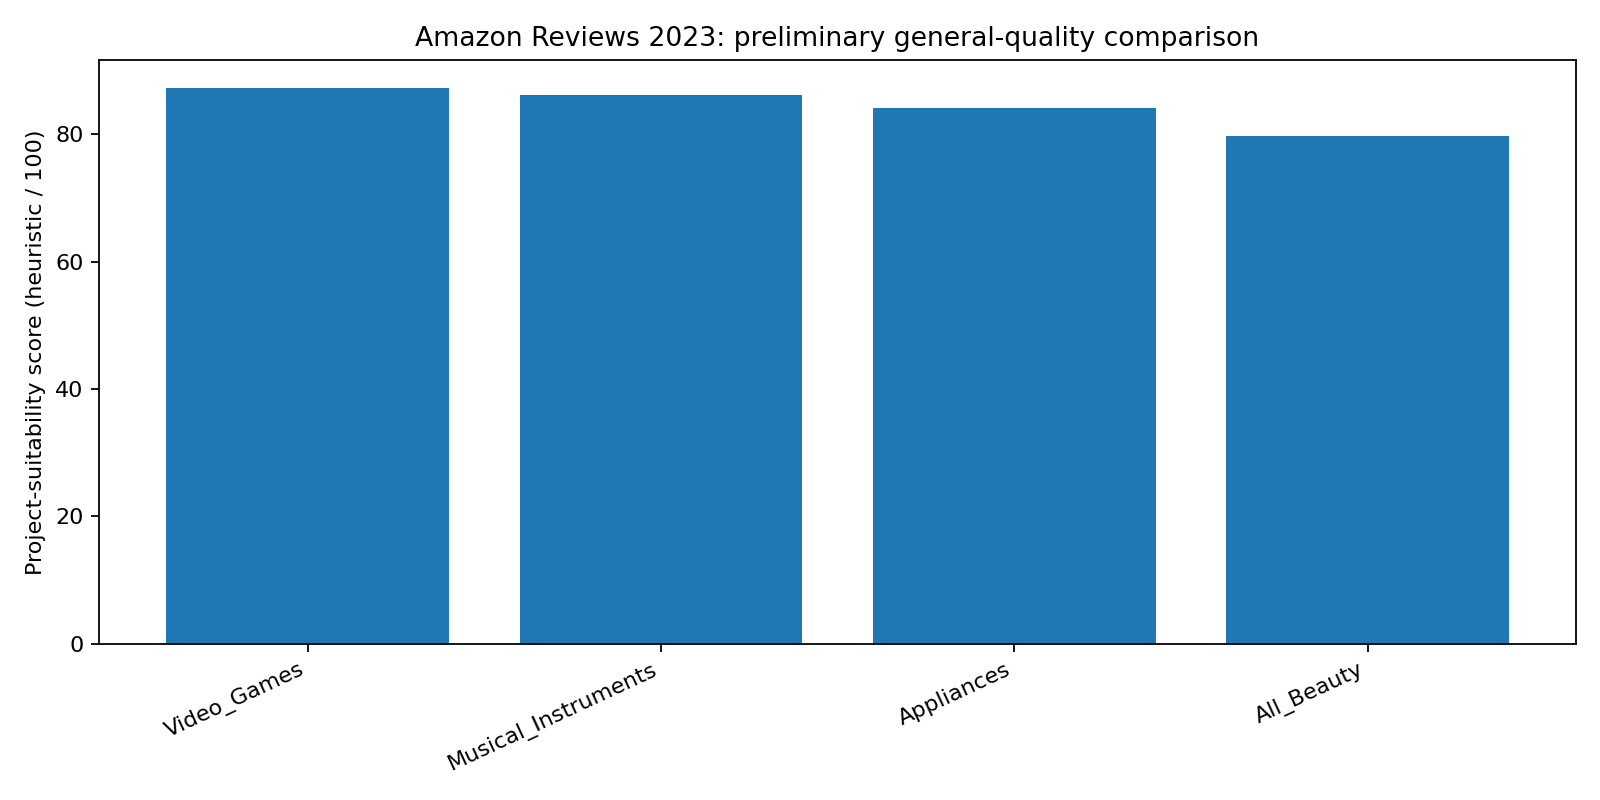

# Preliminary general data-quality audit (not the final selection)

Source: Amazon Reviews 2023; seeded reservoir sample (seed=42).

## General indicators (50% of the final score; normalized to 100% here)

This project prioritizes review text and structured product metadata. Product-image availability is reported but given very little ranking influence because the proposed predictive models do not use images.

- text coverage: **10%**
- long text rate 20 words: **10%**
- metadata join rate: **12%**
- price coverage: **3%**
- image coverage: **1%**
- description coverage: **3%**
- rating entropy: **4%**
- product diversity: **2%**
- temporal coverage: **5%**

Duplicate fingerprints additionally incur a penalty of up to 10 points.

## General-quality-only leaders (not the final category selection)

The final ranking is computed after helpful-vote metrics are audited on full datasets.

- **Video_Games**: 4,600,000 published reviews; 99.9% review-text coverage, 57.8% reviews with >=20 words, 100.0% review-to-product metadata joins, 69.4% price availability, 100.0% product-image availability, 0.74 normalized rating entropy, and 277 months of sampled temporal coverage.
- **Musical_Instruments**: 3,000,000 published reviews; 99.9% review-text coverage, 54.7% reviews with >=20 words, 100.0% review-to-product metadata joins, 68.6% price availability, 100.0% product-image availability, 0.66 normalized rating entropy, and 264 months of sampled temporal coverage.


In [33]:
def reason(row):
    return (
        f"{row['category']}: {int(row['published_reviews']):,} published reviews; "
        f"{row['text_coverage']:.1%} review-text coverage, "
        f"{row['long_text_rate_20_words']:.1%} reviews with >=20 words, "
        f"{row['metadata_join_rate']:.1%} review-to-product metadata joins, "
        f"{row['price_coverage']:.1%} price availability, "
        f"{row['image_coverage']:.1%} product-image availability, "
        f"{row['rating_entropy']:.2f} normalized rating entropy, "
        f"and {row['sample_timespan_months']:.0f} months of sampled temporal coverage."
    )

def save_reports(df, output_dir, is_pilot):
    output_dir.mkdir(parents=True, exist_ok=True)
    df.to_csv(output_dir / "category_comparison_general_only.csv", index=False)
    top = df.head(2).to_dict(orient="records")
    print("Scoring focus: review text + structured metadata; image availability weight = "
          f"{SCORE_WEIGHTS['image_coverage']:.0%} (unified weight).")
    print("\nGENERAL DATA-QUALITY RANKING (provisional, not final)")
    cols = ["category", "quality_score", "text_coverage", "long_text_rate_20_words",
            "metadata_join_rate", "price_coverage", "image_coverage",
            "rating_entropy", "sample_timespan_months"]
    print(df[cols].to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    print("\nGENERAL-QUALITY-ONLY TOP TWO (not final):", ", ".join(x["category"] for x in top))
    for row in top:
        print(" -", reason(row))

    plt.figure(figsize=(10, 5))
    plt.bar(df["category"], df["quality_score"])
    plt.xticks(rotation=25, ha="right")
    plt.ylabel("Project-suitability score (heuristic / 100)")
    plt.title("Amazon Reviews 2023: preliminary general-quality comparison")
    plt.tight_layout()
    plt.savefig(output_dir / "category_scores_general_only.png", dpi=160)
    plt.close()

    with open(output_dir / "category_selection_general_only.md", "w", encoding="utf-8") as f:
        f.write("# Preliminary general data-quality audit (not the final selection)\n\n")
        f.write("Source: Amazon Reviews 2023; seeded reservoir sample (seed=42).\n\n")
        f.write("## General indicators (50% of the final score; normalized to 100% here)\n\n")
        f.write("This project prioritizes review text and structured product metadata. "
                "Product-image availability is reported but given very little ranking influence "
                "because the proposed predictive models do not use images.\n\n")
        for metric, weight in SCORE_WEIGHTS.items():
            if metric not in {"text_coverage", "long_text_rate_20_words", "metadata_join_rate", "price_coverage", "image_coverage", "description_coverage", "rating_entropy", "product_diversity", "temporal_coverage"}:
                continue
            f.write(f"- {metric.replace('_', ' ')}: **{weight:.0%}**\n")
        f.write("\nDuplicate fingerprints additionally incur a penalty of up to 10 points.\n\n")
        if is_pilot:
            f.write("**WARNING:** Pilot evaluated only a prefix of each file, "
                    "so its results might not represent the full category.\n\n")
        f.write("## General-quality-only leaders (not the final category selection)\n\n")
        f.write("The final ranking is computed after helpful-vote metrics are audited on full datasets.\n\n")
        for row in top:
            f.write(f"- **{row['category']}**: {reason(row).removeprefix(row['category'] + ': ')}\n")

save_reports(comparison_df, OUTPUT_DIR, is_pilot=(MAX_REVIEW_ROWS is not None))

print('\nGenerated files:')
for p in sorted(OUTPUT_DIR.glob('*')):
    print(' -', p)

display(Image(filename=str(OUTPUT_DIR / 'category_scores_general_only.png')))
display(Markdown((OUTPUT_DIR / 'category_selection_general_only.md').read_text(encoding='utf-8')))

## Download the preliminary general-quality output

The final unified results archive is generated in the last cell, after the full-file vote audit.

In [34]:
archive = shutil.make_archive(
    '/kaggle/working/amazon_category_selection_general_only_results',
    'zip', root_dir=str(OUTPUT_DIR)
)

## Final combined selection: original data quality + helpful-vote prediction suitability

The following audit scans each of the same **four review files directly from the existing Kaggle inputs**, with no downloads. It counts `helpful_vote` values and reviews per `parent_asin` **over the entire file**. It reports:

- Full helpful-vote count distribution (zero, one, 2–4, 5–9, 10+, median, 90th/99th percentile, maximum).
- Product-review distribution (median, 90th/99th percentile, products with at least 5/10/20 reviews).
- How many products have **at least 10 total reviews and 3 reviews with positive helpful votes**; these offer stronger within-product evidence.
- Number/fraction of reviews with positive labels, fraction attached to sufficiently reviewed products, and a transparent *research-question-specific* ranking.


In [35]:
from collections import Counter
import math
import json
import pandas as pd
from pathlib import Path


def parse_helpful_votes(value):
    """Read a nonnegative integer target; missing/invalid values remain missing."""
    if value is None or isinstance(value, bool):
        return None
    if isinstance(value, int):
        return value if value >= 0 else None
    if isinstance(value, float):
        return int(value) if math.isfinite(value) and value >= 0 and value.is_integer() else None
    if isinstance(value, str) and value.strip().isdigit():
        return int(value.strip())
    return None


def histogram_percentile(hist, quantile):
    """Exact nearest-rank percentile from a histogram; no large arrays needed."""
    total = sum(hist.values())
    if total == 0:
        return float('nan')
    rank = max(1, math.ceil(quantile * total))
    cumulative = 0
    for val, count in sorted(hist.items()):
        cumulative += count
        if cumulative >= rank:
            return val
    return float('nan')


def audit_helpful_votes_full(category, review_path):
    votes_hist = Counter()                 # vote count -> number of reviews
    product_counts = Counter()             # parent_asin -> number of reviews
    positive_by_product = Counter()        # parent_asin -> reviews with >=1 helpful vote
    valid_votes_by_product = Counter()     # parent_asin -> reviews with a valid target
    valid_rows = invalid_json_rows = invalid_votes = missing_product = 0

    print(f"\nScanning {category} (FULL review file) ...", flush=True)
    with open_jsonl(review_path) as f:
        for line in f:
            if not line.strip():
                continue
            try:
                review = json.loads(line)
                if not isinstance(review, dict):
                    raise ValueError('Review row is not an object')
            except (ValueError, json.JSONDecodeError):
                invalid_json_rows += 1
                continue

            valid_rows += 1
            parent = review.get('parent_asin')
            parent = str(parent).strip() if parent is not None else ''
            if parent:
                product_counts[parent] += 1
            else:
                missing_product += 1

            votes = parse_helpful_votes(review.get('helpful_vote'))
            if votes is None:
                invalid_votes += 1
            else:
                votes_hist[votes] += 1
                if parent:
                    valid_votes_by_product[parent] += 1
                    if votes > 0:
                        positive_by_product[parent] += 1

    target_n = sum(votes_hist.values())
    product_n = len(product_counts)
    size_hist = Counter(product_counts.values())
    positive_n = sum(cnt for votes, cnt in votes_hist.items() if votes > 0)
    vote_ge5_n = sum(cnt for votes, cnt in votes_hist.items() if votes >= 5)

    def safe_ratio(num, den):
        return num / den if den else float('nan')

    prod_ge10 = [p for p, count in product_counts.items() if count >= 10]
    reviews_ge10 = sum(product_counts[p] for p in prod_ge10)
    positive_ge10 = sum(positive_by_product[p] for p in prod_ge10)
    valid_ge10 = sum(valid_votes_by_product[p] for p in prod_ge10)
    rich_prod = sum(positive_by_product[p] >= 3 for p in prod_ge10)

    metrics = {
        'category': category,
        'valid_review_rows': valid_rows,
        'invalid_json_rows': invalid_json_rows,
        'valid_helpful_labels': target_n,
        'invalid_or_missing_helpful_labels': invalid_votes,
        'helpful_label_coverage': safe_ratio(target_n, valid_rows),
        'votes_zero_share': safe_ratio(votes_hist[0], target_n),
        'votes_one_share': safe_ratio(votes_hist[1], target_n),
        'votes_2_to_4_share': safe_ratio(sum(votes_hist[v] for v in (2, 3, 4)), target_n),
        'votes_5_to_9_share': safe_ratio(sum(votes_hist[v] for v in range(5, 10)), target_n),
        'votes_10plus_share': safe_ratio(sum(c for v, c in votes_hist.items() if v >= 10), target_n),
        'nonzero_vote_share': safe_ratio(positive_n, target_n),
        'positive_review_count': positive_n,
        'reviews_with_5plus_votes': vote_ge5_n,
        'votes_5plus_share': safe_ratio(vote_ge5_n, target_n),
        'vote_mean': safe_ratio(sum(v * count for v, count in votes_hist.items()), target_n),
        'vote_median': histogram_percentile(votes_hist, 0.50),
        'vote_p90': histogram_percentile(votes_hist, 0.90),
        'vote_p99': histogram_percentile(votes_hist, 0.99),
        'vote_max': max(votes_hist, default=float('nan')),
        'products_with_reviews': product_n,
        'missing_product_id_rows': missing_product,
        'reviews_per_product_mean': safe_ratio(sum(product_counts.values()), product_n),
        'reviews_per_product_median': histogram_percentile(size_hist, 0.50),
        'reviews_per_product_p90': histogram_percentile(size_hist, 0.90),
        'reviews_per_product_p99': histogram_percentile(size_hist, 0.99),
        'reviews_per_product_max': max(size_hist, default=float('nan')),
        'products_with_5plus_reviews': sum(cnt for k, cnt in size_hist.items() if k >= 5),
        'products_with_10plus_reviews': len(prod_ge10),
        'products_with_20plus_reviews': sum(cnt for k, cnt in size_hist.items() if k >= 20),
        'products_with_10plus_reviews_and_3plus_positive_votes': rich_prod,
        'review_share_in_products_with_10plus_reviews': safe_ratio(reviews_ge10, sum(product_counts.values())),
        'positive_reviews_on_products_with_10plus_reviews': positive_ge10,
        'nonzero_vote_share_on_products_with_10plus_reviews': safe_ratio(positive_ge10, valid_ge10),
    }
    return metrics

helpfulness_rows = []
for category in CATEGORIES:
    review_path, _ = available[category]
    if review_path is None:
        print(f'SKIPPING {category}: review file missing')
        continue
    helpfulness_rows.append(audit_helpful_votes_full(category, review_path))

if len(helpfulness_rows) < 2:
    raise RuntimeError('Need review data for at least 2 categories.')

helpfulness_df = pd.DataFrame(helpfulness_rows)
print('\nExact helpful-vote and per-product review statistics computed.')


Scanning All_Beauty (FULL review file) ...

Scanning Appliances (FULL review file) ...

Scanning Video_Games (FULL review file) ...

Scanning Musical_Instruments (FULL review file) ...

Exact helpful-vote and per-product review statistics computed.


HELPFUL VOTES: distributions over all valid labels


,category,valid_helpful_labels,helpful_label_coverage,votes_zero_share,votes_one_share,votes_2_to_4_share,votes_5_to_9_share,votes_10plus_share,nonzero_vote_share,positive_review_count,reviews_with_5plus_votes,vote_mean,vote_median,vote_p90,vote_p99,vote_max
0,All_Beauty,701528,1.0,0.733,0.141,0.086,0.025,0.016,0.267,187439,28338,0.924,0,2,13,646
1,Appliances,2128605,1.0,0.808,0.101,0.057,0.018,0.017,0.192,408620,73836,0.929,0,1,15,5704
2,Video_Games,4624614,1.0,0.747,0.126,0.079,0.026,0.021,0.253,1167726,220580,1.228,0,2,18,10369
3,Musical_Instruments,3017437,1.0,0.720,0.138,0.092,0.029,0.020,0.280,843612,150077,1.137,0,2,16,4650


PRODUCTS: reviews per parent_asin (from the full review files)


,category,products_with_reviews,reviews_per_product_mean,reviews_per_product_median,reviews_per_product_p90,reviews_per_product_p99,products_with_5plus_reviews,products_with_10plus_reviews,products_with_20plus_reviews,review_share_in_products_with_10plus_reviews,products_with_10plus_reviews_and_3plus_positive_votes,positive_reviews_on_products_with_10plus_reviews,nonzero_vote_share_on_products_with_10plus_reviews
0,All_Beauty,112565,6.232,2,11,73,27533,13257,6044,0.659,10026,127438,0.276
1,Appliances,94319,22.568,3,34,334,35894,23491,14640,0.914,17187,369776,0.190
2,Video_Games,137249,33.695,4,51,547,63180,42815,27336,0.941,37372,1082931,0.249
3,Musical_Instruments,213571,14.129,2,22,199,71218,42363,23840,0.855,36373,698400,0.271


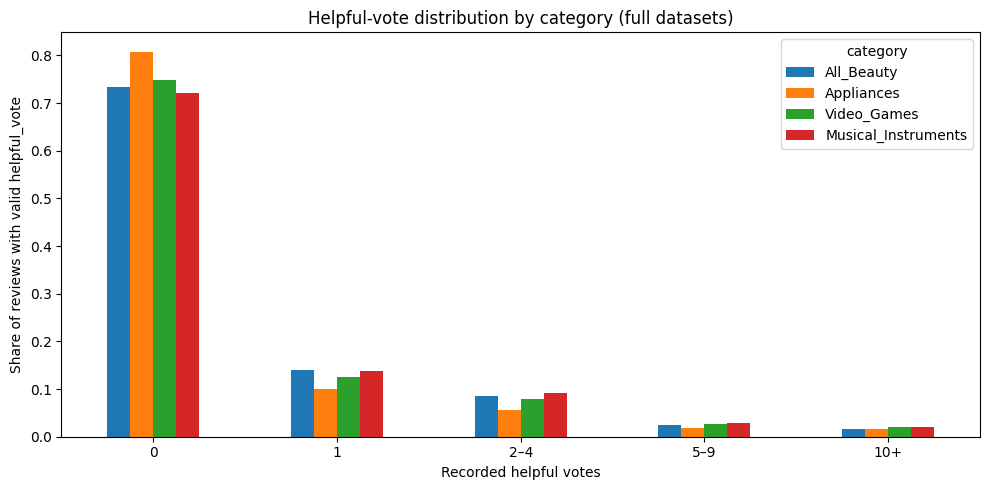

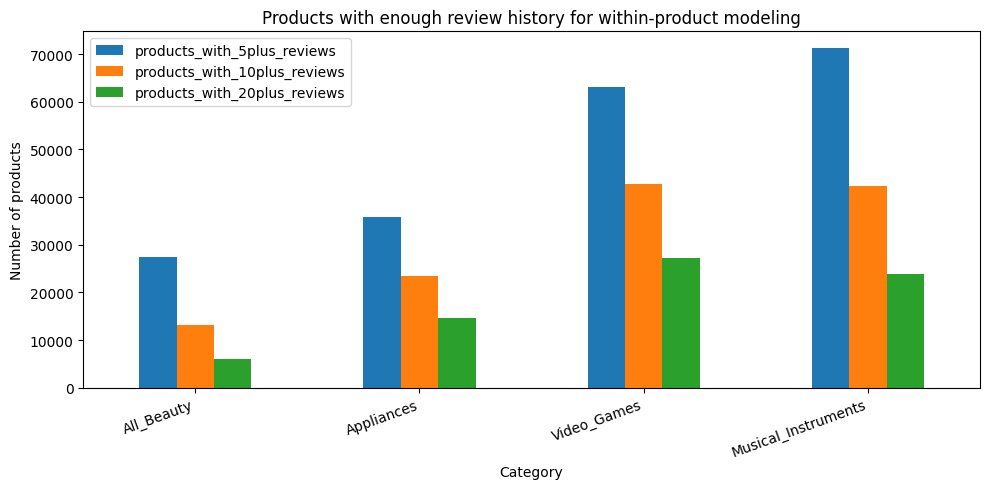

In [36]:
vote_columns = [
    'category', 'valid_helpful_labels', 'helpful_label_coverage',
    'votes_zero_share', 'votes_one_share', 'votes_2_to_4_share',
    'votes_5_to_9_share', 'votes_10plus_share', 'nonzero_vote_share',
    'positive_review_count', 'reviews_with_5plus_votes',
    'vote_mean', 'vote_median', 'vote_p90', 'vote_p99', 'vote_max'
]
product_columns = [
    'category', 'products_with_reviews', 'reviews_per_product_mean',
    'reviews_per_product_median', 'reviews_per_product_p90',
    'reviews_per_product_p99', 'products_with_5plus_reviews',
    'products_with_10plus_reviews', 'products_with_20plus_reviews',
    'review_share_in_products_with_10plus_reviews',
    'products_with_10plus_reviews_and_3plus_positive_votes',
    'positive_reviews_on_products_with_10plus_reviews',
    'nonzero_vote_share_on_products_with_10plus_reviews'
]
print('HELPFUL VOTES: distributions over all valid labels')
display(helpfulness_df[vote_columns].round(3))
print('PRODUCTS: reviews per parent_asin (from the full review files)')
display(helpfulness_df[product_columns].round(3))

# Two independent charts: the chart is diagnostic, not a substitute for the tables.
import matplotlib.pyplot as plt
vote_shares = ['votes_zero_share','votes_one_share','votes_2_to_4_share',
               'votes_5_to_9_share','votes_10plus_share']
vote_names = ['0','1','2–4','5–9','10+']
plot_df = helpfulness_df.set_index('category')[vote_shares].copy()
plot_df.columns = vote_names
ax = plot_df.T.plot(kind='bar', figsize=(10,5))
ax.set_ylabel('Share of reviews with valid helpful_vote')
ax.set_xlabel('Recorded helpful votes')
ax.set_title('Helpful-vote distribution by category (full datasets)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

ax = helpfulness_df.set_index('category')[[
    'products_with_5plus_reviews','products_with_10plus_reviews',
    'products_with_20plus_reviews'
]].plot(kind='bar', figsize=(10,5))
ax.set_ylabel('Number of products')
ax.set_xlabel('Category')
ax.set_title('Products with enough review history for within-product modeling')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### Final decision rule for the research question

The **unified** ranking combines all nine general data-quality indicators with six helpful-vote / product-history indicators. Adjust the 15 weights in the first code cell (`SCORE_WEIGHTS`), not in a separate dictionary. Their weights sum to 1.0.

- **50% general quality:** text, metadata joins, rating diversity, timestamps, and related data quality.
- **30% helpful-vote availability and signal:** label coverage, fraction with nonzero votes, fraction with at least five votes, and positive review count.
- **20% product review history:** number of products with >=10 reviews and >=3 positive-vote reviews, and fraction of reviews belonging to products with >=10 reviews.

The two raw count metrics use `log1p` followed by min–max normalization across the compared categories; the other indicators are already [0,1] fractions or normalized quantities. The final score is `100 × weighted sum − 10 × duplicate fingerprint rate`, clipped to [0,100].



FINAL UNIFIED RANKING: general quality + predicting recorded helpful-vote counts


,category,research_suitability_score,quality_score,helpful_label_coverage,nonzero_vote_share,votes_5plus_share,positive_review_count,products_with_10plus_reviews_and_3plus_positive_votes,review_share_in_products_with_10plus_reviews,vote_median,vote_p90,vote_p99,reviews_per_product_median,reviews_per_product_p90,text_coverage,metadata_join_rate,duplicate_fingerprint_rate
0,Video_Games,78.27,87.31,1.0,0.253,0.048,1167726,37372,0.941,0,2,18,4,51,0.999,1.0,0.0
1,Musical_Instruments,76.07,86.07,1.0,0.280,0.050,843612,36373,0.855,0,2,16,2,22,0.999,1.0,0.0
2,Appliances,68.49,84.06,1.0,0.192,0.035,408620,17187,0.914,0,1,15,3,34,0.999,1.0,0.0
3,All_Beauty,59.21,79.71,1.0,0.267,0.040,187439,10026,0.659,0,2,13,2,11,0.999,1.0,0.0



TOP TWO FOR THIS RESEARCH QUESTION: Video_Games, Musical_Instruments

Caveats: This uses cumulative votes; exposure/impression counts are unavailable.
Examine zero-vote rates and median reviews/product before finalizing selection.


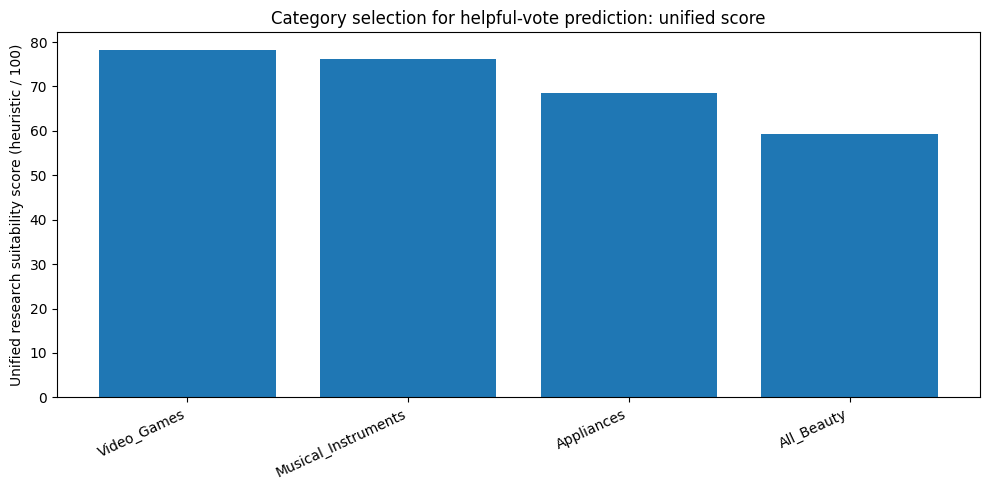


Saved final unified score and audit files in: /kaggle/working/category_selection


In [37]:
import numpy as np

ranked_df = comparison_df.merge(
    helpfulness_df,
    on='category', how='inner', validate='one_to_one'
)

GENERAL_METRICS = {
    'text_coverage', 'long_text_rate_20_words', 'metadata_join_rate',
    'price_coverage', 'image_coverage', 'description_coverage',
    'rating_entropy', 'product_diversity', 'temporal_coverage'
}
HELPFULNESS_METRICS = set(SCORE_WEIGHTS) - GENERAL_METRICS
COUNT_METRICS = {
    'positive_review_count',
    'products_with_10plus_reviews_and_3plus_positive_votes',
}
assert GENERAL_METRICS | HELPFULNESS_METRICS == set(SCORE_WEIGHTS)
assert abs(sum(SCORE_WEIGHTS.values()) - 1.0) < 1e-9


def min_max_across_categories(values):
    s = pd.Series(values, dtype='float64')
    lo, hi = s.min(), s.max()
    if not np.isfinite(lo) or not np.isfinite(hi):
        raise ValueError('Missing/nonfinite metric: inspect the full-file audits.')
    if hi == lo:
        return pd.Series([0.5] * len(s), index=s.index)
    return (s - lo) / (hi - lo)


# Each metric is actually used by the unified score (not merely listed in the weights).
ranked_df['score_before_duplicate_penalty'] = 0.0
for metric, weight in SCORE_WEIGHTS.items():
    values = ranked_df[metric].astype(float)
    if metric in COUNT_METRICS:
        values = min_max_across_categories(np.log1p(values))
    elif not (np.isfinite(values).all() and values.between(0, 1).all()):
        raise ValueError(f'Expected [0,1] score factor: {metric}')

    ranked_df['normalized_' + metric] = values
    ranked_df['score_before_duplicate_penalty'] += 100 * weight * values

ranked_df['research_suitability_score'] = (
    ranked_df['score_before_duplicate_penalty']
    - 10 * ranked_df['duplicate_fingerprint_rate']
).clip(0, 100).round(2)
ranked_df = ranked_df.sort_values(
    'research_suitability_score', ascending=False
).reset_index(drop=True)

important = [
    'category', 'research_suitability_score', 'quality_score',
    'helpful_label_coverage', 'nonzero_vote_share', 'votes_5plus_share',
    'positive_review_count', 'products_with_10plus_reviews_and_3plus_positive_votes',
    'review_share_in_products_with_10plus_reviews',
    'vote_median', 'vote_p90', 'vote_p99',
    'reviews_per_product_median', 'reviews_per_product_p90',
    'text_coverage', 'metadata_join_rate', 'duplicate_fingerprint_rate'
]
print('FINAL UNIFIED RANKING: general quality + predicting recorded helpful-vote counts')
display(ranked_df[important].round(3))
selected = ranked_df.head(2)['category'].tolist()
print('\nTOP TWO FOR THIS RESEARCH QUESTION:', ', '.join(selected))
print('\nCaveats: This uses cumulative votes; exposure/impression counts are unavailable.')
print('Examine zero-vote rates and median reviews/product before finalizing selection.')

# Persist all metrics, transparent per-factor contributions, and the final ranking.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
helpfulness_df.to_csv(OUTPUT_DIR / 'helpful_vote_distribution_and_products.csv', index=False)
ranked_df.to_csv(OUTPUT_DIR / 'category_comparison_UNIFIED.csv', index=False)

plt.figure(figsize=(10, 5))
plt.bar(ranked_df['category'], ranked_df['research_suitability_score'])
plt.xticks(rotation=25, ha='right')
plt.ylabel('Unified research suitability score (heuristic / 100)')
plt.title('Category selection for helpful-vote prediction: unified score')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'category_scores_UNIFIED.png', dpi=160)
plt.show()

with open(OUTPUT_DIR / 'category_selection_UNIFIED.md', 'w', encoding='utf-8') as f:
    f.write('# Category selection for predicting recorded helpful votes\n\n')
    f.write('These are data-suitability heuristics, not estimated model accuracies.\n\n')
    f.write('## Unified scoring weights\n\n')
    for metric, weight in SCORE_WEIGHTS.items():
        f.write(f'- {metric}: **{weight:.0%}**\n')
    f.write('\nCounts use log1p + min-max across the compared categories. '
            'Other factors are [0,1] indicators; a sample duplicate penalty is applied.\n\n')
    f.write('## Ranked comparison\n\n')
    f.write(ranked_df[important].round(3).to_markdown(index=False))
    f.write('\n\n## Recommended two categories under this heuristic\n\n')
    f.write(', '.join(selected) + '\n\n')
    f.write('## Critical limitations\n\n')
    f.write('- Helpful votes confound intrinsic usefulness with review exposure and age.\n')
    f.write('- Historical vote trajectories are not included.\n')
    f.write('- Zero-heavy counts may make exact regression difficult.\n')
    f.write('- Median reviews per product can be low even with many total reviews.\n')
    f.write('- Scores and rankings are sensitive to relative normalization and chosen weights.\n')
    f.write('- Group- and time-aware evaluation is essential before claiming generalization.\n')
print('\nSaved final unified score and audit files in:', OUTPUT_DIR)


In [38]:
archive_with_helpfulness = shutil.make_archive(
    '/kaggle/working/amazon_category_selection_unified_results',
    'zip', root_dir=str(OUTPUT_DIR)
)
print('Results archive:', archive_with_helpfulness)


Results archive: /kaggle/working/amazon_category_selection_unified_results.zip


In [39]:

# Compare 50/50 and 40/60 scoring schemes

import numpy as np
import pandas as pd

# Verify the current weights represent the original 50/50 scheme
assert np.isclose(
    sum(SCORE_WEIGHTS[m] for m in GENERAL_METRICS), 0.50
)
assert np.isclose(
    sum(SCORE_WEIGHTS[m] for m in HELPFULNESS_METRICS), 0.50
)

# Create a new 40/60 weighting scheme
WEIGHTS_40_60 = {
    metric: weight * (
        0.40 / 0.50 if metric in GENERAL_METRICS
        else 0.60 / 0.50
    )
    for metric, weight in SCORE_WEIGHTS.items()
}

assert np.isclose(sum(WEIGHTS_40_60.values()), 1.0)

print("40/60 weights:")
display(pd.DataFrame({
    "metric": list(SCORE_WEIGHTS),
    "weight_50_50": list(SCORE_WEIGHTS.values()),
    "weight_40_60": [
        WEIGHTS_40_60[m] for m in SCORE_WEIGHTS
    ]
}))

# Recalculate using the normalized factors from the existing audit
def calculate_score(weights, df):
    total = np.zeros(len(df), dtype=float)

    for metric, weight in weights.items():
        total += (
            100 * weight
            * df["normalized_" + metric].to_numpy(dtype=float)
        )

    penalty = 10 * df["duplicate_fingerprint_rate"].to_numpy(dtype=float)

    return np.clip(total - penalty, 0, 100)

# Compare scores
sensitivity_df = ranked_df[["category"]].copy()

sensitivity_df["score_50_50"] = ranked_df[
    "research_suitability_score"
]

sensitivity_df["score_40_60"] = calculate_score(
    WEIGHTS_40_60, ranked_df
).round(2)

# Rank categories for each weighting scheme
for scheme in ["50_50", "40_60"]:
    sensitivity_df["rank_" + scheme] = (
        sensitivity_df["score_" + scheme]
        .rank(ascending=False, method="min")
        .astype(int)
    )

sensitivity_df["score_change"] = (
    sensitivity_df["score_40_60"]
    - sensitivity_df["score_50_50"]
).round(2)

sensitivity_df["rank_improvement"] = (
    sensitivity_df["rank_50_50"]
    - sensitivity_df["rank_40_60"]
)

sensitivity_df = sensitivity_df.sort_values(
    "rank_40_60"
).reset_index(drop=True)

print("\n50/50 versus 40/60 comparison:")
display(sensitivity_df)

print("\nTop two under 50/50:")
print(
    sensitivity_df.nsmallest(2, "rank_50_50")["category"].tolist()
)

print("\nTop two under 40/60:")
print(
    sensitivity_df.nsmallest(2, "rank_40_60")["category"].tolist()
)


40/60 weights:


,metric,weight_50_50,weight_40_60
0,text_coverage,0.10,0.080
1,long_text_rate_20_words,0.10,0.080
2,metadata_join_rate,0.12,0.096
3,price_coverage,0.03,0.024
4,image_coverage,0.01,0.008
5,description_coverage,0.03,0.024
6,rating_entropy,0.04,0.032
7,product_diversity,0.02,0.016
8,temporal_coverage,0.05,0.040
9,helpful_label_coverage,0.08,0.096



50/50 versus 40/60 comparison:


,category,score_50_50,score_40_60,rank_50_50,rank_40_60,score_change,rank_improvement
0,Video_Games,78.27,76.46,1,1,-1.81,0
1,Musical_Instruments,76.07,74.07,2,2,-2.00,0
2,Appliances,68.49,65.38,3,3,-3.11,0
3,All_Beauty,59.21,55.11,4,4,-4.10,0



Top two under 50/50:
['Video_Games', 'Musical_Instruments']

Top two under 40/60:
['Video_Games', 'Musical_Instruments']


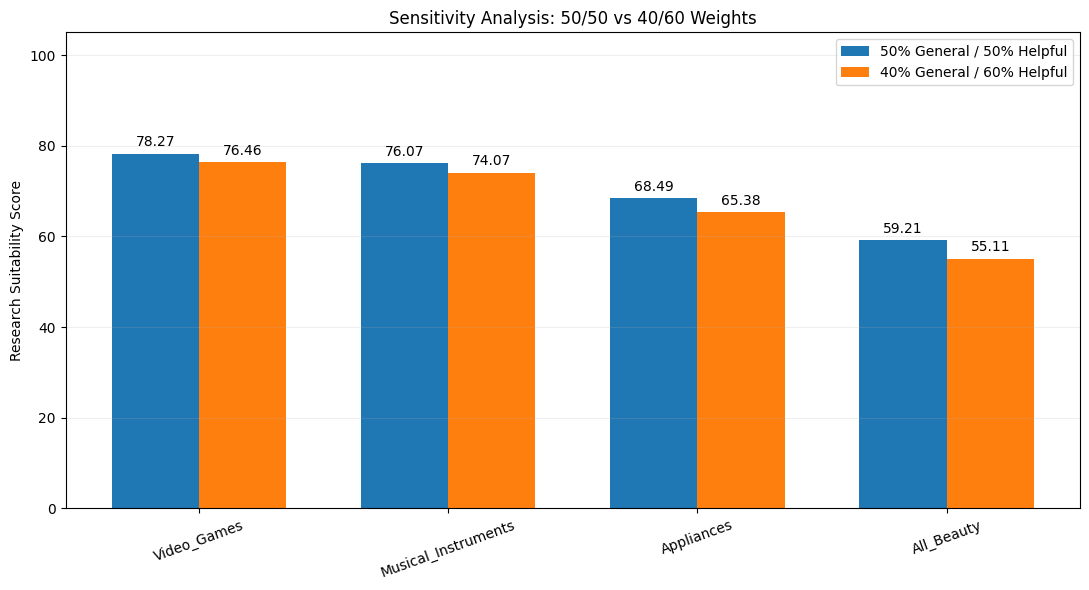

The top two categories are stable across both schemes.


In [40]:

# Visual comparison of both scoring schemes

plot_df = sensitivity_df.sort_values("rank_50_50")

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    plot_df["score_50_50"],
    width,
    label="50% General / 50% Helpful"
)

bars2 = ax.bar(
    x + width / 2,
    plot_df["score_40_60"],
    width,
    label="40% General / 60% Helpful"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["category"], rotation=20)
ax.set_ylabel("Research Suitability Score")
ax.set_title("Sensitivity Analysis: 50/50 vs 40/60 Weights")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.2)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    OUTPUT_DIR / "weight_sensitivity_50_50_vs_40_60.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Save numerical results
sensitivity_df.to_csv(
    OUTPUT_DIR / "weight_sensitivity_comparison.csv",
    index=False
)

# Check whether the top two are stable
top_50 = set(
    sensitivity_df.nsmallest(2, "rank_50_50")["category"]
)
top_40 = set(
    sensitivity_df.nsmallest(2, "rank_40_60")["category"]
)

if top_50 == top_40:
    print("The top two categories are stable across both schemes.")
else:
    print("The top two categories CHANGE when weights change.")
    print("50/50:", top_50)
    print("40/60:", top_40)


---

## Additional evidence before selecting the final research category

The following three experiments **supplement** the 50/50 and 40/60 heuristic rankings; they do not change their weights:

1. **Temporal audit:** How does the *recorded* helpful-vote distribution vary by review **publication year**?
2. **Product-level audit:** How does the distribution vary with the **number of reviews per product** (`parent_asin`)?
3. **Predictive pilot:** On a reproducible sample from each selected category, can structured features and review text predict *recorded cumulative helpful-vote counts* better than a zero/median baseline?

Only the **two categories selected under 40/60** are scanned here. The temporal and product analyses use their **entire attached review files**; the model uses a **uniform reservoir sample** for manageable Kaggle runtime. The new scan is necessary because earlier cells saved aggregate counts but not per-review examples. **No download is performed.**

**Interpretation warning:** Review creation time is known, but the date at which helpful votes were observed and the number of review impressions are not. Publication-year comparisons are descriptive and confounded by exposure. A chronological split by publication date is a useful robustness check, **not** a genuine historical vote-count forecasting backtest.


In [41]:
# Settings for the new experiments
PILOT_SEED = SEED
PILOT_SAMPLE_SIZE = 40_000  
PILOT_TRAIN_FRACTION = 0.80
TEMPORAL_PLOT_MIN_REVIEWS = 1000 
PILOT_MAX_TEXT_CHARS = 4_000
# The two selected by the existing 40/60 analysis, NOT a manually chosen category:
PILOT_CATEGORIES = sensitivity_df.sort_values('rank_40_60')['category'].head(2).tolist()
assert 0 < PILOT_TRAIN_FRACTION < 1
assert PILOT_SAMPLE_SIZE >= 1000
assert len(PILOT_CATEGORIES) == 2
for cat in PILOT_CATEGORIES:
    assert available[cat][0] is not None, f'Missing Kaggle review input: {cat}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Testing these two categories:', PILOT_CATEGORIES)
print('Uniform review sample per category (maximum):', f'{PILOT_SAMPLE_SIZE:,}')


Testing these two categories: ['Video_Games', 'Musical_Instruments']
Uniform review sample per category (maximum): 40,000


### One scan for the temporal and product-level audits, plus the pilot sample

The scan counts products and vote totals **exactly** across each full review file, while separately keeping a reproducible random sample of eligible reviews. Products are grouped by their actual number of reviews in the full file, not by their sampled count.

A product with more reviews may also attract more attention. Differences below are **associations**, not evidence that having more reviews *causes* any review to receive more votes.


In [42]:
import random
import math
import json
from collections import Counter, defaultdict
from datetime import datetime, timezone
import numpy as np
import pandas as pd

PRODUCT_SIZE_BINS = [0, 4, 9, 49, 199, float('inf')]
PRODUCT_SIZE_NAMES = ['1–4', '5–9', '10–49', '50–199', '200+']

def publication_year_utc(timestamp):
    """Amazon Reviews '23 timestamps are milliseconds since epoch (UTC)."""
    if timestamp is None or isinstance(timestamp, bool):
        return None, None
    try:
        value = float(timestamp)
        if not math.isfinite(value):
            return None, None
        dt = datetime.fromtimestamp(value / 1000.0, tz=timezone.utc)
        if not 1990 <= dt.year <= 2030:
            return None, None
        return dt.year, int(value)
    except (ValueError, TypeError, OverflowError, OSError):
        return None, None

def product_review_bin(n):
    if n <= 4: return '1–4'
    if n <= 9: return '5–9'
    if n <= 49: return '10–49'
    if n <= 199: return '50–199'
    return '200+'

def scan_selected_category(category, path, k=PILOT_SAMPLE_SIZE, seed=PILOT_SEED):
    rng = random.Random(seed)
    products = Counter()         # all valid JSON reviews, including invalid vote labels
    vote_n = Counter()           # product ID -> valid label count
    vote_positive = Counter()    # product ID -> vote >0 count
    vote_ge5 = Counter()         # product ID -> vote >=5 count
    vote_sum = Counter()         # product ID -> sum of helpful-vote counts
    year_stats = defaultdict(lambda: {'reviews': 0, 'positive': 0,
                                        'votes_5plus': 0, 'votes_sum': 0, 'hist': Counter()})
    sample = []
    eligible_for_sample = rows = bad_json = bad_votes = bad_time = missing_product = 0

    print(f'Full-file temporal/product scan: {category}', flush=True)
    with open_jsonl(path) as f:
        for line in f:
            if not line.strip():
                continue
            try:
                r = json.loads(line)
                if not isinstance(r, dict):
                    raise ValueError('Expected JSON object')
            except (ValueError, json.JSONDecodeError):
                bad_json += 1
                continue
            rows += 1
            pid = str(r.get('parent_asin') or '').strip()
            if pid:
                products[pid] += 1
            else:
                missing_product += 1

            v = parse_helpful_votes(r.get('helpful_vote'))  # existing parser
            if v is None:
                bad_votes += 1
                continue
            if pid:
                vote_n[pid] += 1
                vote_sum[pid] += v
                if v > 0:
                    vote_positive[pid] += 1
                if v >= 5:
                    vote_ge5[pid] += 1

            year, ts = publication_year_utc(r.get('timestamp'))
            if year is None:
                bad_time += 1
                continue
            stats = year_stats[year]
            stats['reviews'] += 1
            stats['positive'] += int(v > 0)
            stats['votes_5plus'] += int(v >= 5)
            stats['votes_sum'] += v
            stats['hist'][v] += 1

            # Store only fields needed for the fair predictive pilot.
            # Reservoir sampling gives each eligible review equal inclusion probability.
            if not pid:
                continue
            eligible_for_sample += 1
            record = {
                'category': category,
                'parent_asin': pid,
                'timestamp_ms': ts,
                'review_year': year,
                'review_month': datetime.fromtimestamp(ts / 1000.0, tz=timezone.utc).month,
                'rating': r.get('rating'),
                'verified_purchase': r.get('verified_purchase'),
                'text': str(r.get('text') or '')[:PILOT_MAX_TEXT_CHARS],
                'title': str(r.get('title') or '')[:300],
                'helpful_vote': v,
            }
            if len(sample) < k:
                sample.append(record)
            else:
                j = rng.randrange(eligible_for_sample)
                if j < k:
                    sample[j] = record
            if rows % 1_000_000 == 0:
                print(f'  {rows:,} reviews...', flush=True)

    # These aggregates are REVIEW-weighted, using complete parent_asin histories.
    group_stats = defaultdict(lambda: {'products': 0, 'reviews': 0,
                                        'valid_votes': 0, 'positive': 0,
                                        'votes_5plus': 0, 'votes_sum': 0})
    for pid, n_reviews in products.items():
        b = product_review_bin(n_reviews)
        g = group_stats[b]
        g['products'] += 1
        g['reviews'] += n_reviews
        g['valid_votes'] += vote_n[pid]
        g['positive'] += vote_positive[pid]
        g['votes_5plus'] += vote_ge5[pid]
        g['votes_sum'] += vote_sum[pid]

    temporal = pd.DataFrame([
        {'category': category, 'publication_year': y,
         'review_count': st['reviews'],
         'nonzero_vote_share': st['positive'] / st['reviews'],
         'votes_5plus_share': st['votes_5plus'] / st['reviews'],
         'mean_helpful_votes': st['votes_sum'] / st['reviews'],
         'vote_median': histogram_percentile(st['hist'], 0.5),
         'vote_p90': histogram_percentile(st['hist'], 0.9),
         'vote_p99': histogram_percentile(st['hist'], 0.99),
         'votes_zero_share': st['hist'][0] / st['reviews']}
        for y, st in sorted(year_stats.items())
    ])
    by_product_size = pd.DataFrame([
        {'category': category, 'product_review_group': b,
         'product_count': group_stats[b]['products'],
         'review_count': group_stats[b]['reviews'],
         'valid_helpful_labels': group_stats[b]['valid_votes'],
         'nonzero_vote_share': (group_stats[b]['positive'] / group_stats[b]['valid_votes']
                                 if group_stats[b]['valid_votes'] else np.nan),
         'votes_5plus_share': (group_stats[b]['votes_5plus'] / group_stats[b]['valid_votes']
                               if group_stats[b]['valid_votes'] else np.nan),
         'mean_helpful_votes': (group_stats[b]['votes_sum'] / group_stats[b]['valid_votes']
                                if group_stats[b]['valid_votes'] else np.nan)}
        for b in PRODUCT_SIZE_NAMES
    ])
    diagnostics = {
        'category': category, 'valid_json_reviews': rows,
        'invalid_json_rows': bad_json, 'invalid_or_missing_votes': bad_votes,
        'valid_votes_missing_timestamp': bad_time,
        'missing_parent_asin': missing_product,
        'pilot_eligible_reviews': eligible_for_sample,
        'pilot_sample_reviews': len(sample),
        'unique_products': len(products),
    }
    return temporal, by_product_size, pd.DataFrame(sample), diagnostics

temporal_pieces, product_pieces, pilot_pieces, scan_diagnostics = [], [], [], []
for cat in PILOT_CATEGORIES:
    review_path, _ = available[cat]
    temporal, product_groups, pilot, diag = scan_selected_category(cat, review_path)
    temporal_pieces.append(temporal)
    product_pieces.append(product_groups)
    pilot_pieces.append(pilot)
    scan_diagnostics.append(diag)

temporal_df = pd.concat(temporal_pieces, ignore_index=True)
product_group_df = pd.concat(product_pieces, ignore_index=True)
pilot_df = pd.concat(pilot_pieces, ignore_index=True)
scan_diagnostics_df = pd.DataFrame(scan_diagnostics)

for name, dataframe in [
    ('temporal_helpful_votes_by_publication_year.csv', temporal_df),
    ('product_size_helpful_votes.csv', product_group_df),
    ('additional_scan_diagnostics.csv', scan_diagnostics_df),
]:
    dataframe.to_csv(OUTPUT_DIR / name, index=False)
print('Full-file diagnostic summary:')
display(scan_diagnostics_df)
print('Pilot sample sizes:', pilot_df['category'].value_counts().to_dict())


Full-file temporal/product scan: Video_Games
  1,000,000 reviews...
  2,000,000 reviews...
  3,000,000 reviews...
  4,000,000 reviews...
Full-file temporal/product scan: Musical_Instruments
  1,000,000 reviews...
  2,000,000 reviews...
  3,000,000 reviews...
Full-file diagnostic summary:


,category,valid_json_reviews,invalid_json_rows,invalid_or_missing_votes,valid_votes_missing_timestamp,missing_parent_asin,pilot_eligible_reviews,pilot_sample_reviews,unique_products
0,Video_Games,4624615,0,1,0,0,4624614,40000,137249
1,Musical_Instruments,3017439,0,2,0,0,3017437,40000,213571


Pilot sample sizes: {'Video_Games': 40000, 'Musical_Instruments': 40000}


### Experiment 1 — Temporal analysis

These are **review publication-year cohorts**, not vote collection dates. The results show how currently recorded counts differ for reviews published in different years; they cannot reconstruct how votes accumulated. The chart hides years with fewer than `TEMPORAL_PLOT_MIN_REVIEWS` reviews, but the CSV preserves all observed cohorts.


,category,publication_year,review_count,nonzero_vote_share,votes_5plus_share,mean_helpful_votes,vote_median,vote_p90,vote_p99,votes_zero_share
0,Video_Games,1998,6,0.6667,0.3333,3.0000,1,9,9,0.3333
1,Video_Games,1999,458,0.9541,0.6616,14.2860,8,31,92,0.0459
2,Video_Games,2000,4825,0.8651,0.4230,8.0410,3,19,78,0.1349
3,Video_Games,2001,10832,0.7422,0.2747,4.7319,2,11,43,0.2578
4,Video_Games,2002,14349,0.6791,0.2268,4.1349,1,9,40,0.3209
5,Video_Games,2003,14130,0.7336,0.2409,4.9301,2,10,56,0.2664
6,Video_Games,2004,15269,0.8188,0.3070,6.2184,2,12,65,0.1812
7,Video_Games,2005,16678,0.8633,0.3598,6.4837,3,13,61,0.1367
8,Video_Games,2006,16467,0.8663,0.3658,6.9086,3,13,69,0.1337
9,Video_Games,2007,28768,0.7043,0.2254,4.8654,1,10,57,0.2957


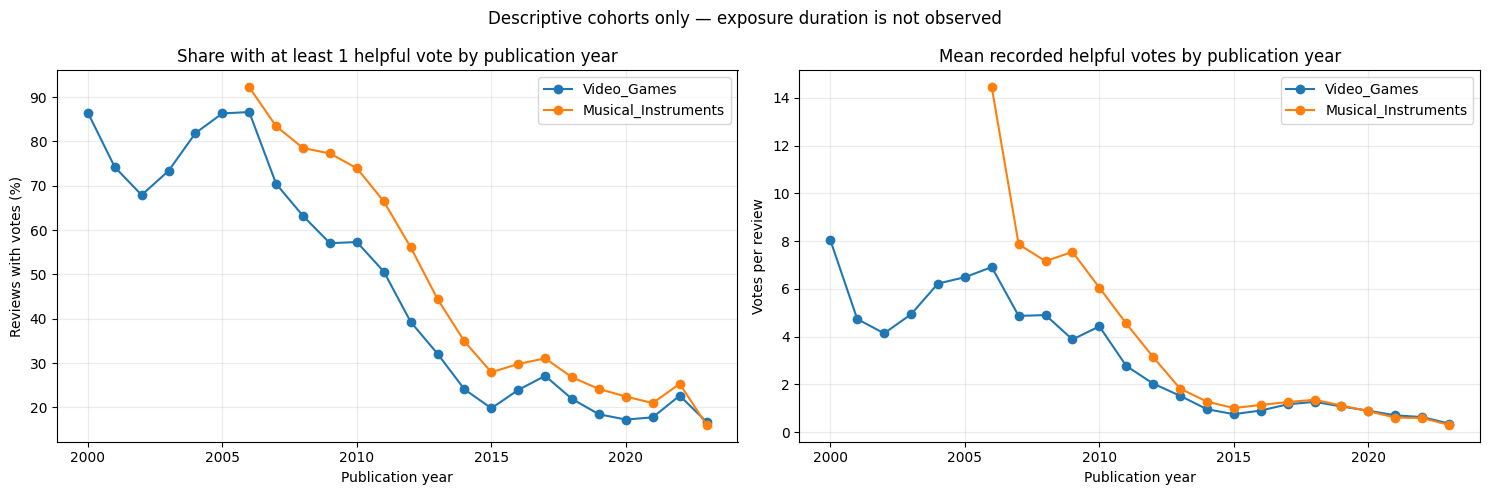

In [43]:
display(temporal_df.round(4))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for cat in PILOT_CATEGORIES:
    s = temporal_df.loc[(temporal_df['category'] == cat) &
                        (temporal_df['review_count'] >= TEMPORAL_PLOT_MIN_REVIEWS)]
    axes[0].plot(s['publication_year'], 100*s['nonzero_vote_share'], marker='o', label=cat)
    axes[1].plot(s['publication_year'], s['mean_helpful_votes'], marker='o', label=cat)
axes[0].set(title='Share with at least 1 helpful vote by publication year',
            xlabel='Publication year', ylabel='Reviews with votes (%)')
axes[1].set(title='Mean recorded helpful votes by publication year',
            xlabel='Publication year', ylabel='Votes per review')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle('Descriptive cohorts only — exposure duration is not observed')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'temporal_vote_patterns.png', dpi=160, bbox_inches='tight')
plt.show()


### Experiment 2 — Product-level analysis

Each product is grouped by its **full-file number of reviews** (`parent_asin`). The percentage with nonzero votes and average helpful votes are **review-weighted**. The product count describes how many distinct products contribute to each group.


,category,product_review_group,product_count,review_count,valid_helpful_labels,nonzero_vote_share,votes_5plus_share,mean_helpful_votes
0,Video_Games,1–4,74069,136567,136567,0.2877,0.0404,0.8371
1,Video_Games,5–9,20365,135100,135100,0.3368,0.0567,1.1027
2,Video_Games,10–49,28825,624611,624611,0.3294,0.0645,1.2444
3,Video_Games,50–199,9853,957523,957522,0.2916,0.0596,1.3261
4,Video_Games,200+,4137,2770814,2770814,0.2158,0.0397,1.2157
5,Musical_Instruments,1–4,142353,249141,249141,0.3023,0.0392,0.7945
6,Musical_Instruments,5–9,28855,189568,189568,0.3687,0.0573,1.0718
7,Musical_Instruments,10–49,32200,667889,667889,0.3643,0.0678,1.2492
8,Musical_Instruments,50–199,8038,742215,742213,0.3024,0.0614,1.2563
9,Musical_Instruments,200+,2125,1168626,1168626,0.1974,0.0330,1.0812


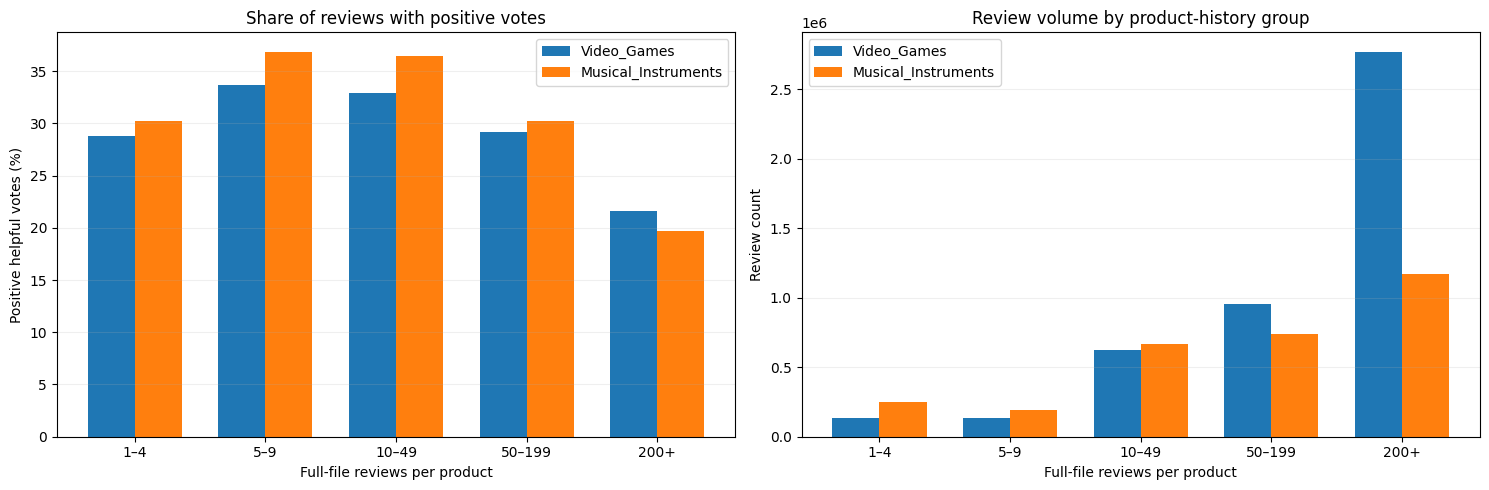

In [44]:
display(product_group_df.round(4))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
xs = np.arange(len(PRODUCT_SIZE_NAMES))
bar_width = 0.36
for i, cat in enumerate(PILOT_CATEGORIES):
    s = (product_group_df[product_group_df['category'] == cat]
         .set_index('product_review_group').reindex(PRODUCT_SIZE_NAMES))
    shift = (i - (len(PILOT_CATEGORIES)-1)/2) * bar_width
    axes[0].bar(xs + shift, 100*s['nonzero_vote_share'], width=bar_width, label=cat)
    axes[1].bar(xs + shift, s['review_count'], width=bar_width, label=cat)
axes[0].set(title='Share of reviews with positive votes', ylabel='Positive helpful votes (%)')
axes[1].set(title='Review volume by product-history group', ylabel='Review count')
for ax in axes:
    ax.set_xticks(xs, PRODUCT_SIZE_NAMES)
    ax.set_xlabel('Full-file reviews per product')
    ax.legend()
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'product_history_vote_patterns.png', dpi=160, bbox_inches='tight')
plt.show()
